# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Para exibir todas as colunas no pandas
pd.set_option('display.max_columns', None)

In [4]:
# Modifique o caminho do arquivo conforme a estrutura do seu projeto
DATA_PATH = "../data/data_raw/customer_churn_telecom_services.csv" 

df = pd.read_csv(DATA_PATH)


print(f"Dimensões do Dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Dimensões do Dataset: 7043 linhas e 20 colunas.


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


## Análise das variáveis numéricas

### Análise de valores faltantes

In [17]:
missing_summary = pd.DataFrame({
    'Valores Nulos (Qtd)': df.isnull().sum(),
    'Porcentagem (%)': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[missing_summary['Valores Nulos (Qtd)'] > 0]

if not missing_summary.empty:
    print("Colunas com Valores Ausentes")
    display(missing_summary)
else:
    print("Nenhum valor nulo encontrado diretamente após a limpeza inicial.")

Colunas com Valores Ausentes


,Valores Nulos (Qtd),Porcentagem (%)
TotalCharges,11,0.156183


In [28]:
(df['TotalCharges'] == 0).sum()

np.int64(0)

In [31]:
(df['TotalCharges'] == 0.0).sum()

np.int64(0)

Nenhum totalcharges tinha valor zero, ou era um float ou nan

In [33]:
df[df['TotalCharges'].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [34]:
df[df['TotalCharges'].isna()][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [36]:
df[df['tenure'] == 0]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Achamos o motivo de existirem os valores faltantes, era relativos aos 11 novos clientes. Não tinha chego o dia do pagamento ainda, dessa forma vamos optar a inputar 0.0 nessas instâncias

### Análise de outliers

In [19]:
# Análise de variáveis numéricas continuas/discretas
num_cols = df.select_dtypes(include=[np.number]).columns

print("Estatísticas Descritivas --> Variáveis Numéricas")
df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

Estatísticas Descritivas --> Variáveis Numéricas


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


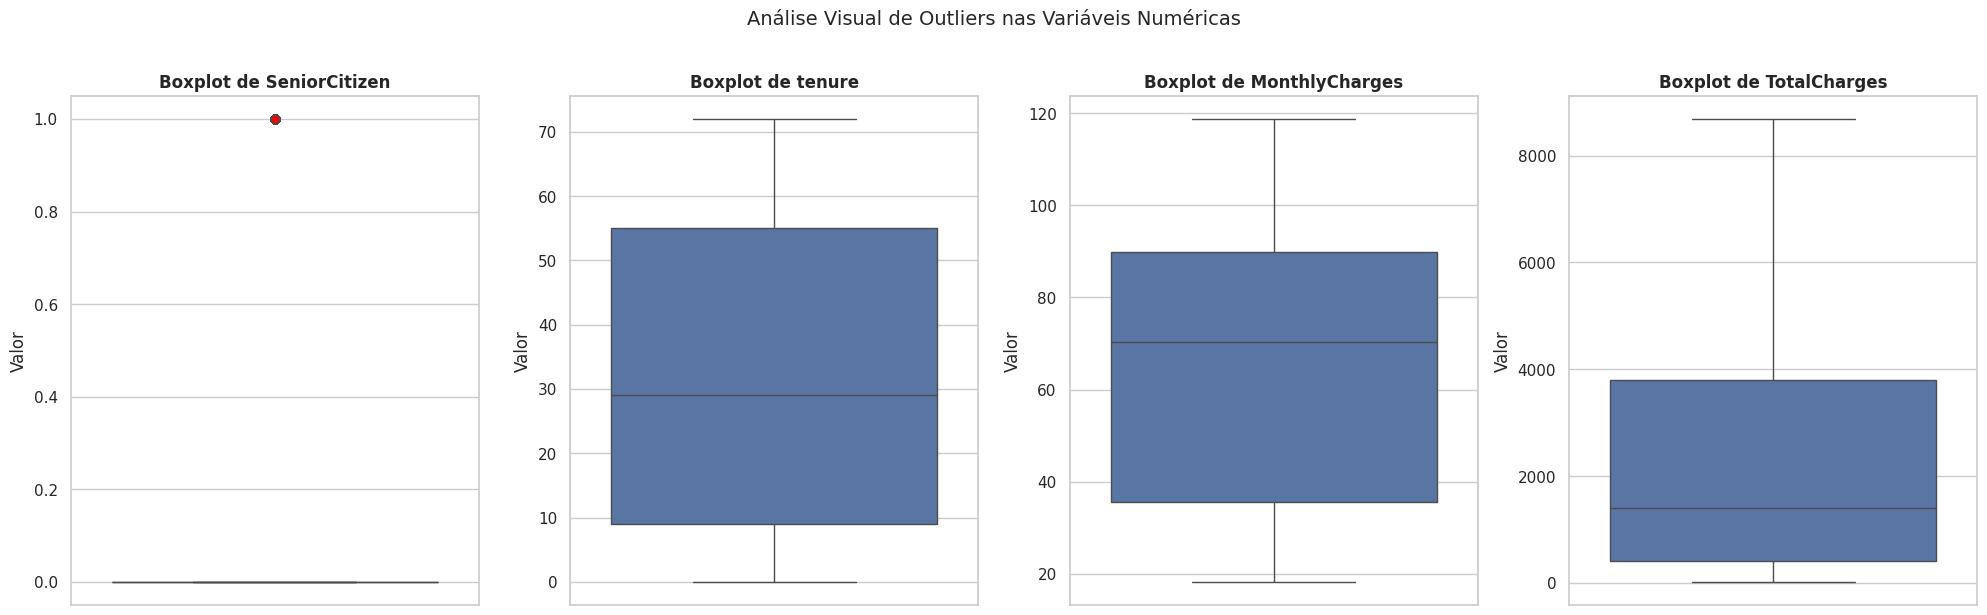

In [ ]:
num_cols = [col for col in df.select_dtypes(include=[np.number]).columns ]

# Configura o grid de subplots
n_cols = len(num_cols)
fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 6))

if n_cols == 1:
    axes = [axes]

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="#4C72B0", flierprops={"markerfacecolor": "red", "marker": "o"})
    axes[i].set_title(f"Boxplot de {col}", fontsize=12, fontweight="bold")
    axes[i].set_ylabel("Valor")

plt.suptitle("Análise Visual de Outliers nas Variáveis Numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Análise das distribuições

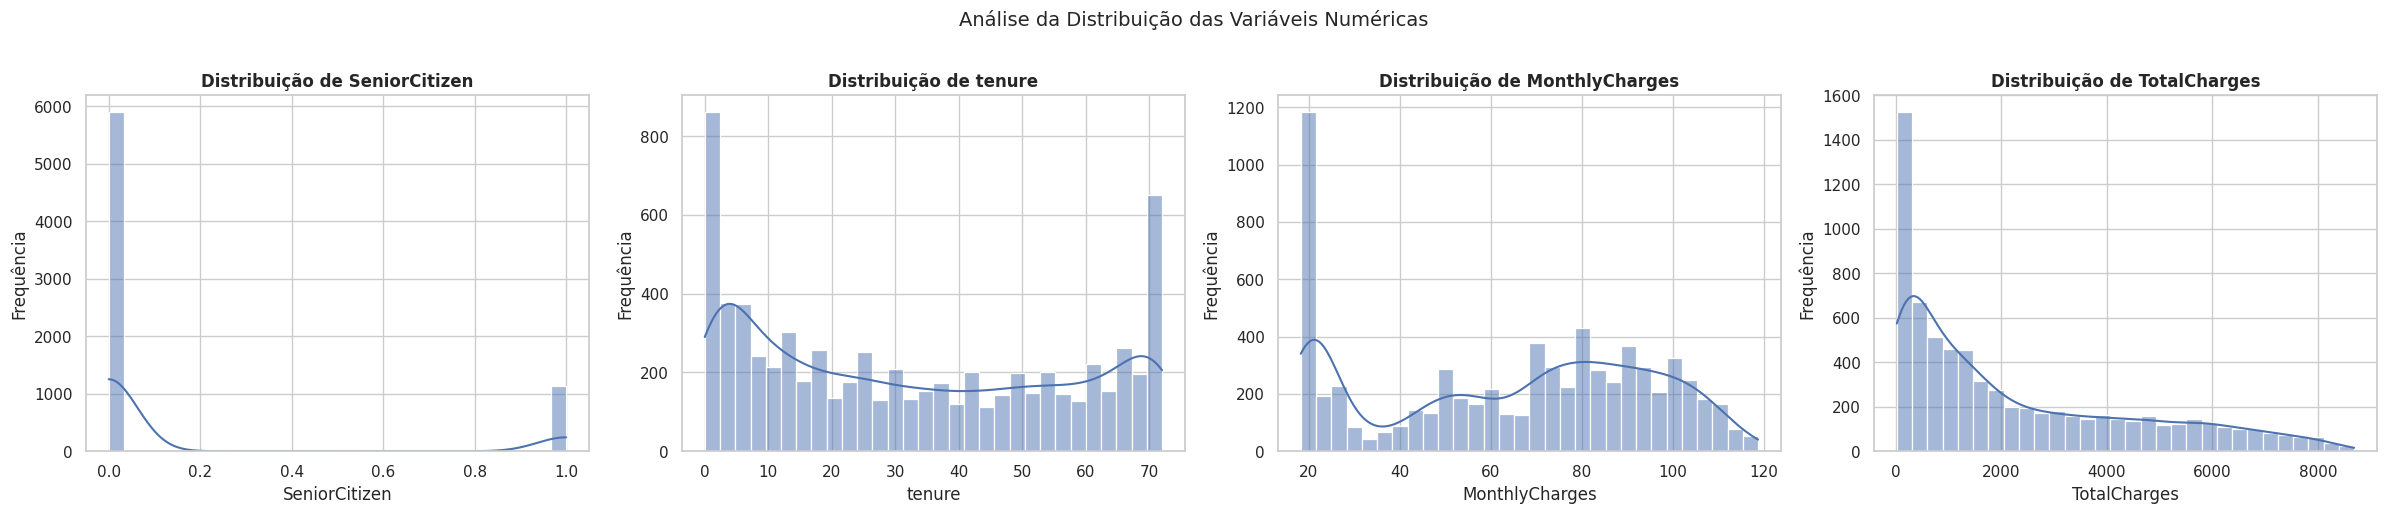

In [24]:
# Seleciona as variáveis numéricas contínuas
num_cols = [col for col in df.select_dtypes(include=[np.number]).columns ]

fig, axes = plt.subplots(1, len(num_cols), figsize=(6 * len(num_cols), 5))

if len(num_cols) == 1:
    axes = [axes]

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color="#4C72B0", bins=30)
    axes[i].set_title(f"Distribuição de {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequência")

plt.suptitle("Análise da Distribuição das Variáveis Numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Análise das variáveis categóricas

In [20]:
cat_cols = df.select_dtypes(include=['object']).columns

cat_summary = pd.DataFrame({
    'Valores Únicos': df[cat_cols].nunique(),
    'Exemplo de Valores': [df[col].unique()[:3].tolist() for col in cat_cols]
})

print("Resumo de Variáveis Categóricas")
display(cat_summary)

Resumo de Variáveis Categóricas


,Valores Únicos,Exemplo de Valores
gender,2,"[Female, Male]"
Partner,2,"[Yes, No]"
Dependents,2,"[No, Yes]"
PhoneService,2,"[No, Yes]"
MultipleLines,3,"[No phone service, No, Yes]"
InternetService,3,"[DSL, Fiber optic, No]"
OnlineSecurity,3,"[No, Yes, No internet service]"
OnlineBackup,3,"[Yes, No, No internet service]"
DeviceProtection,3,"[No, Yes, No internet service]"
TechSupport,3,"[No, Yes, No internet service]"


### Target

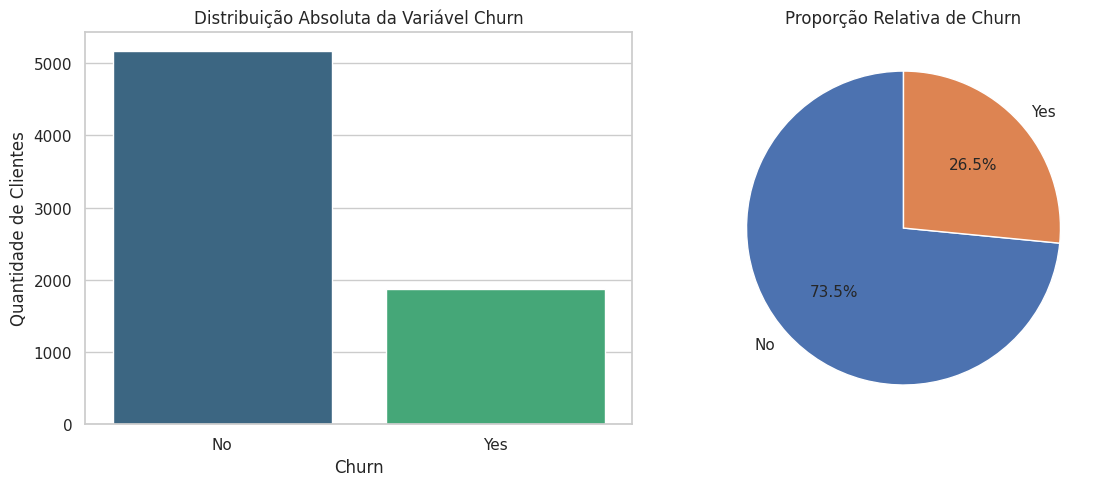

In [15]:
target_col = "Churn"

if target_col in df.columns:
    churn_counts = df[target_col].value_counts()
    churn_perc = df[target_col].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Gráfico de Barras
    sns.countplot(data=df, x=target_col, hue=target_col, ax=ax[0], palette="viridis", legend=False)
    ax[0].set_title("Distribuição Absoluta da Variável Churn")
    ax[0].set_ylabel("Quantidade de Clientes")

    # Gráfico de Pizza
    ax[1].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'], startangle=90)
    ax[1].set_title("Proporção Relativa de Churn")

    plt.tight_layout()
    plt.show()
